# Recursive 7-Day Forecast Evaluation (evaluation-only, no retraining)

The thesis panel suggested that, to be genuinely useful, the final product should forecast
further ahead than 1 day (e.g. a week). This notebook tests that suggestion directly instead
of arguing about it in prose: it takes the **already-trained** LSTM and XGBoost artifacts from
`models/v2_static/` (same architecture, same hyperparameters, same Box-Cox lambda, same
Min-Max scaler, same 70-day lookback window, same train/test split at `DATA_CUTOFF`) and rolls
them forward **recursively** — feeding each day's own prediction back into the lookback window
in place of the true value — out to a 7-day horizon.

This notebook does **not** retrain anything and does **not** write to `models/v2_static/` or
any artifact directory the Streamlit site depends on. It is purely an evaluation of a different
question: *how far ahead can the existing, already-locked pipeline usefully forecast?*

Conclusion up front (justified with numbers at the bottom of this notebook): recursive
multi-step forecasting is technically possible with this architecture, but it is not adopted
for the main deliverable, because the error growth compounds an underprediction problem that
is already present at 1-day lead.


In [1]:
import os
from pathlib import Path

_start = Path.cwd()
for _cand in [_start, *_start.parents]:
    if (_cand / "2619492.csv").exists() and (_cand / "streamlit_dashboard").is_dir():
        os.chdir(_cand)
        break
else:
    raise RuntimeError(f"Could not find repo root (looked for 2619492.csv) starting from {_start}")

print(f"Working directory set to repo root: {Path.cwd()}")


Working directory set to repo root: C:\Users\Dell\Desktop\Thesis


In [2]:
import json
import math
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb
import tensorflow as tf
from IPython.display import Markdown, display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Imports ready.")


Imports ready.


In [3]:
# ---------------------------------------------------------------------------
# Load the already-trained artifacts from the locked STATIC pipeline. We are
# NOT retraining -- extending the forecast horizon is a change in evaluation
# methodology, not a new model, and retraining here would muddy that
# argument. DATA_CUTOFF / TOTAL_DATA_LENGTH are not stored in metadata.json,
# so they are hardcoded here to match runs/static/..._STATIC.ipynb exactly;
# do not change them independently of that notebook.
# ---------------------------------------------------------------------------
TRAIN_DATA_CANDIDATES = ['2619492.csv', 'Data/2619492.csv', 'content/2619492.csv']

DATA_CUTOFF = 9058
TOTAL_DATA_LENGTH = 10988
HORIZON = 7  # forecast out to 7 days ahead, recursively

STATIC_MODEL_DIR = Path("models") / "v2_static"

with open(STATIC_MODEL_DIR / "metadata.json") as f:
    static_metadata = json.load(f)

WINDOW_SIZE = static_metadata['lstm_config']['window_size']
lam_value = static_metadata['preprocessing']['box_cox_lambda']
w_lstm = static_metadata['ensemble']['weight_lstm']
w_xgb = static_metadata['ensemble']['weight_xgb']

print(f"Loaded STATIC metadata: window_size={WINDOW_SIZE}, box_cox_lambda={lam_value:.6f}, "
      f"weight_lstm={w_lstm:.4f}, weight_xgb={w_xgb:.4f}")

lstm_model = tf.keras.models.load_model(STATIC_MODEL_DIR / "lstm_model.keras")
xgb_model = xgb.XGBRegressor()
xgb_model.load_model(str(STATIC_MODEL_DIR / "xgboost_model.json"))
scaler = joblib.load(STATIC_MODEL_DIR / "scaler.joblib")

print("Loaded already-trained LSTM, XGBoost, and scaler artifacts from models/v2_static/ "
      "(no retraining performed in this notebook).")


Loaded STATIC metadata: window_size=70, box_cox_lambda=-1.438692, weight_lstm=0.4826, weight_xgb=0.5174


Loaded already-trained LSTM, XGBoost, and scaler artifacts from models/v2_static/ (no retraining performed in this notebook).


In [4]:
# ---------------------------------------------------------------------------
# Helper functions (mirrors runs/static, redefined here so this notebook is
# self-contained -- lambda is fixed/reused, never refit).
# ---------------------------------------------------------------------------
def inv_boxcox1p(bcdata, lam):
    return inv_boxcox(bcdata, lam) - 1


def split_sequences(series, window):
    x, y = [], []
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        x.append(series[i:end])
        y.append(series[end])
    return np.array(x), np.array(y)


def safe_mape(y_true, y_pred, min_actual=0.1):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    pct_errors = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    return float(np.mean(pct_errors) * 100.0), int(mask.sum())


def horizon_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape, mape_n = safe_mape(y_true, y_pred)
    bias = float(np.mean(y_pred - y_true))
    return {'RMSE': rmse, 'MAE': mae, 'MAPE (%)': mape, 'MAPE_n': mape_n, 'Bias (mean error)': bias}


def make_anchor_windows(series, window, horizon):
    """Every anchor position with `window` days of history and at least
    `horizon` true future days available to score against."""
    n = len(series) - window - horizon + 1
    if n <= 0:
        raise ValueError("Test series too short for the requested window + horizon")
    windows = np.stack([series[i:i + window] for i in range(n)])
    futures = np.stack([series[i + window:i + window + horizon] for i in range(n)])
    return windows, futures

print("Helper functions defined.")


Helper functions defined.


In [5]:
# ---------------------------------------------------------------------------
# Reproduce the exact preprocessing of the STATIC notebook, but apply the
# *already-fit* Box-Cox lambda and MinMaxScaler instead of refitting them
# (refitting would silently create a slightly different transform than the
# one the loaded models were actually trained on).
# ---------------------------------------------------------------------------
csv_path = next((p for p in TRAIN_DATA_CANDIDATES if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError(f"Could not find training data. Searched: {TRAIN_DATA_CANDIDATES}")

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
print(f"Loaded {len(rainfall)} records from {csv_path}")

inv_data = boxcox(rainfall.PRCP.to_numpy() + 1, lmbda=lam_value)
rain_data_scaled = scaler.transform(inv_data.reshape(-1, 1))[:, 0]

lstm_series = rain_data_scaled[:TOTAL_DATA_LENGTH]
xgb_series = inv_data[:TOTAL_DATA_LENGTH]

# Same train/test split point as STATIC -- we only need the test half here.
lstm_test_series = lstm_series[DATA_CUTOFF:]
xgb_test_series = xgb_series[DATA_CUTOFF:]

print(f"Test series length: {len(lstm_test_series)}")


Loaded 11323 records from 2619492.csv
Test series length: 1930


In [6]:
# ---------------------------------------------------------------------------
# Sanity check: reproduce the STATIC notebook's single-step (1-day-ahead,
# non-recursive) numbers with the reloaded artifacts before doing anything
# recursive. If these don't match closely, the recursive results below
# would not be trustworthy either.
# ---------------------------------------------------------------------------
x_test, y_test = split_sequences(lstm_test_series, WINDOW_SIZE)
x_test = x_test.reshape(-1, WINDOW_SIZE, 1)
x_test_lag, y_test_lag = split_sequences(xgb_test_series, WINDOW_SIZE)

y_test_bc = scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0]
y_test_orig = inv_boxcox1p(y_test_bc, lam_value)
y_test_lag_orig = inv_boxcox1p(y_test_lag, lam_value)
assert np.allclose(y_test_orig, y_test_lag_orig, atol=1e-6), "LSTM and XGBoost targets must match"

lstm_pred_scaled = lstm_model.predict(x_test, verbose=0)
lstm_pred_bc = scaler.inverse_transform(lstm_pred_scaled)[:, 0]
lstm_pred_orig = inv_boxcox1p(lstm_pred_bc, lam_value)

xgb_pred_bc = xgb_model.predict(x_test_lag)
xgb_pred_orig = inv_boxcox1p(xgb_pred_bc, lam_value)

ensemble_pred_orig = w_lstm * lstm_pred_orig + w_xgb * xgb_pred_orig

lstm_rmse_1day = math.sqrt(mean_squared_error(y_test_orig, lstm_pred_orig))
xgb_rmse_1day = math.sqrt(mean_squared_error(y_test_orig, xgb_pred_orig))
ens_rmse_1day = math.sqrt(mean_squared_error(y_test_orig, ensemble_pred_orig))

print("1-day-ahead sanity check (single-step, non-recursive, reproduces STATIC notebook):")
print(f"  LSTM RMSE:     {lstm_rmse_1day:.4f}  (STATIC metadata: {static_metadata['evaluation']['lstm']['rmse']:.4f})")
print(f"  XGBoost RMSE:  {xgb_rmse_1day:.4f}  (STATIC metadata: {static_metadata['evaluation']['xgboost']['rmse']:.4f})")
print(f"  Ensemble RMSE: {ens_rmse_1day:.4f}  (STATIC metadata: {static_metadata['evaluation']['ensemble']['rmse']:.4f})")

lstm_diff = abs(lstm_rmse_1day - static_metadata['evaluation']['lstm']['rmse'])
xgb_diff = abs(xgb_rmse_1day - static_metadata['evaluation']['xgboost']['rmse'])
if xgb_diff > 1e-4:
    print(f"WARNING: XGBoost reload RMSE differs by {xgb_diff:.6f} (expected ~0, XGBoost is deterministic).")
if lstm_diff > 0.05:
    print(f"WARNING: LSTM reload RMSE differs by {lstm_diff:.4f} (small drift can be normal, large drift is not).")
else:
    print("\nSanity check passed: reloaded artifacts reproduce the STATIC notebook's 1-day-ahead numbers.")


1-day-ahead sanity check (single-step, non-recursive, reproduces STATIC notebook):
  LSTM RMSE:     5.9586  (STATIC metadata: 5.9586)
  XGBoost RMSE:  5.5320  (STATIC metadata: 5.5320)
  Ensemble RMSE: 5.6419  (STATIC metadata: 5.6419)

Sanity check passed: reloaded artifacts reproduce the STATIC notebook's 1-day-ahead numbers.


In [7]:
# ---------------------------------------------------------------------------
# Recursive (iterated) multi-step forecasting: to forecast day t+2, the
# model's own predicted t+1 value is fed back into the lookback window in
# place of the true value, and so on out to t+7. This is done independently
# for LSTM (in scaled Box-Cox space, matching how it was trained) and
# XGBoost (in unscaled Box-Cox space, matching how it was trained). The
# ensemble at each lead day is the same fixed inverse-RMSE weights from
# models/v2_static/metadata.json applied to each model's own recursive
# prediction at that lead day.
# ---------------------------------------------------------------------------
lstm_windows, lstm_futures = make_anchor_windows(lstm_test_series, WINDOW_SIZE, HORIZON)
xgb_windows, xgb_futures = make_anchor_windows(xgb_test_series, WINDOW_SIZE, HORIZON)
n_anchors = lstm_windows.shape[0]
print(f"Number of recursive-forecast anchor points in the test period: {n_anchors}")

# True future values, in original precipitation units -- identical for both
# models since they come from the same underlying series (just represented
# in scaled vs. unscaled Box-Cox space).
true_future_orig = inv_boxcox1p(xgb_futures, lam_value)  # shape (n_anchors, HORIZON)

lstm_recursive_windows = lstm_windows.copy()
xgb_recursive_windows = xgb_windows.copy()

lstm_preds_scaled_by_h = []
xgb_preds_bc_by_h = []

recursive_start = time.time()
for h in range(1, HORIZON + 1):
    lstm_input = lstm_recursive_windows.reshape(-1, WINDOW_SIZE, 1)
    step_lstm_scaled = lstm_model.predict(lstm_input, verbose=0).flatten()
    lstm_preds_scaled_by_h.append(step_lstm_scaled)
    lstm_recursive_windows = np.concatenate(
        [lstm_recursive_windows[:, 1:], step_lstm_scaled.reshape(-1, 1)], axis=1)

    step_xgb_bc = xgb_model.predict(xgb_recursive_windows)
    xgb_preds_bc_by_h.append(step_xgb_bc)
    xgb_recursive_windows = np.concatenate(
        [xgb_recursive_windows[:, 1:], step_xgb_bc.reshape(-1, 1)], axis=1)

    print(f"  Recursive step {h}/{HORIZON} done")
recursive_seconds = time.time() - recursive_start
print(f"Recursive rollout for all {n_anchors} anchors x {HORIZON} lead days complete in {recursive_seconds:.1f}s")

lstm_pred_orig_by_h = np.zeros((n_anchors, HORIZON))
xgb_pred_orig_by_h = np.zeros((n_anchors, HORIZON))
for h in range(HORIZON):
    lstm_bc_h = scaler.inverse_transform(lstm_preds_scaled_by_h[h].reshape(-1, 1))[:, 0]
    lstm_pred_orig_by_h[:, h] = inv_boxcox1p(lstm_bc_h, lam_value)
    xgb_pred_orig_by_h[:, h] = inv_boxcox1p(xgb_preds_bc_by_h[h], lam_value)

ensemble_pred_orig_by_h = w_lstm * lstm_pred_orig_by_h + w_xgb * xgb_pred_orig_by_h

# Naive persistence baseline: repeat the last known actual value (the final
# day of the 70-day lookback window) forward for every lead day -- the
# simplest possible forecast and the reference point for whether the models
# actually learned something useful at each horizon.
last_known_bc = xgb_windows[:, -1]
last_known_orig = inv_boxcox1p(last_known_bc, lam_value)
persistence_pred_orig_by_h = np.tile(last_known_orig.reshape(-1, 1), (1, HORIZON))

print("Recursive forecasts and persistence baseline computed for all anchors and lead days.")


Number of recursive-forecast anchor points in the test period: 1854


  Recursive step 1/7 done


  Recursive step 2/7 done


  Recursive step 3/7 done


  Recursive step 4/7 done


  Recursive step 5/7 done


  Recursive step 6/7 done


  Recursive step 7/7 done
Recursive rollout for all 1854 anchors x 7 lead days complete in 7.9s
Recursive forecasts and persistence baseline computed for all anchors and lead days.


In [8]:
# ---------------------------------------------------------------------------
# RMSE / MAE / MAPE / bias for each lead day (1-7), for LSTM, XGBoost,
# Ensemble, and the naive persistence baseline.
# ---------------------------------------------------------------------------
records = []
for h in range(HORIZON):
    lead_day = h + 1
    y_true_h = true_future_orig[:, h]
    for name, preds in [
        ('LSTM', lstm_pred_orig_by_h[:, h]),
        ('XGBoost', xgb_pred_orig_by_h[:, h]),
        ('Ensemble', ensemble_pred_orig_by_h[:, h]),
        ('Persistence (naive)', persistence_pred_orig_by_h[:, h]),
    ]:
        m = horizon_metrics(y_true_h, preds)
        m['Model'] = name
        m['Lead day'] = lead_day
        records.append(m)

df_horizon = pd.DataFrame(records)[['Lead day', 'Model', 'RMSE', 'MAE', 'MAPE (%)', 'MAPE_n', 'Bias (mean error)']]
pd.set_option('display.width', 120)
print(df_horizon.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


 Lead day               Model   RMSE    MAE  MAPE (%)  MAPE_n  Bias (mean error)
        1                LSTM 5.9681 2.2784   93.5800     781            -2.2005
        1             XGBoost 5.5402 3.1396  176.7319     781            -0.0980
        1            Ensemble 5.6508 2.6169  101.5713     781            -1.1127
        1 Persistence (naive) 7.4948 3.4838  305.2529     781            -0.0013
        2                LSTM 5.9678 2.2788   93.4400     782            -2.2002
        2             XGBoost 5.5544 3.1876  176.7743     782            -0.0470
        2            Ensemble 5.6543 2.6404  101.2700     782            -1.0862
        2 Persistence (naive) 7.9248 3.8686  277.5103     782            -0.0020
        3                LSTM 5.9673 2.2790   93.2845     783            -2.1993
        3             XGBoost 5.5566 3.1034  166.1161     783            -0.1970
        3            Ensemble 5.6694 2.6055   97.0485     783            -1.1634
        3 Persistence (naive

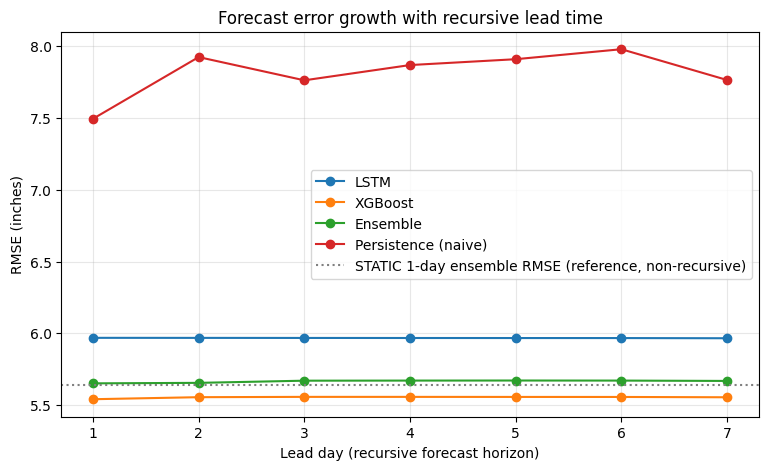

In [9]:
# ---------------------------------------------------------------------------
# RMSE vs. lead day: the error-growth curve the whole argument rests on.
# ---------------------------------------------------------------------------
plt.figure(figsize=(9, 5))
for name in ['LSTM', 'XGBoost', 'Ensemble', 'Persistence (naive)']:
    sub = df_horizon[df_horizon['Model'] == name]
    plt.plot(sub['Lead day'], sub['RMSE'], marker='o', label=name)
plt.axhline(static_metadata['evaluation']['ensemble']['rmse'], color='gray', linestyle=':',
            label='STATIC 1-day ensemble RMSE (reference, non-recursive)')
plt.xlabel('Lead day (recursive forecast horizon)')
plt.ylabel('RMSE (inches)')
plt.title('Forecast error growth with recursive lead time')
plt.xticks(range(1, HORIZON + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


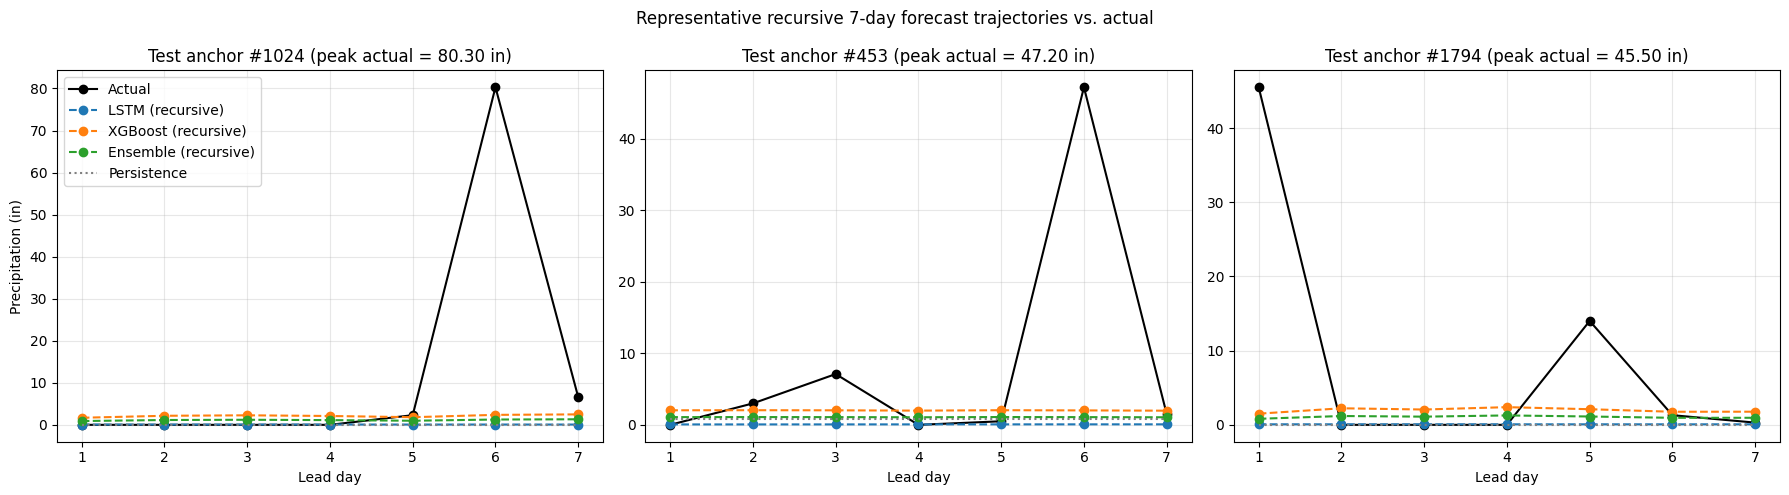

In [10]:
# ---------------------------------------------------------------------------
# Qualitative complement to the RMSE table: pick a few representative
# anchors around real rain events and plot the full recursive trajectory
# (all 7 lead days) against the actual values, to show visually how the
# forecast drifts/flattens as the horizon extends.
# ---------------------------------------------------------------------------
event_intensity = true_future_orig.max(axis=1)
candidate_order = np.argsort(-event_intensity)

selected_anchors = []
min_gap = WINDOW_SIZE  # keep the examples independent (non-overlapping lookback windows)
for idx in candidate_order:
    if all(abs(int(idx) - s) >= min_gap for s in selected_anchors):
        selected_anchors.append(int(idx))
    if len(selected_anchors) == 3:
        break

lead_days = np.arange(1, HORIZON + 1)
fig, axes = plt.subplots(1, len(selected_anchors), figsize=(6 * len(selected_anchors), 5), sharey=False)
if len(selected_anchors) == 1:
    axes = [axes]
for ax, idx in zip(axes, selected_anchors):
    ax.plot(lead_days, true_future_orig[idx], 'k-o', label='Actual')
    ax.plot(lead_days, lstm_pred_orig_by_h[idx], '--o', label='LSTM (recursive)')
    ax.plot(lead_days, xgb_pred_orig_by_h[idx], '--o', label='XGBoost (recursive)')
    ax.plot(lead_days, ensemble_pred_orig_by_h[idx], '--o', label='Ensemble (recursive)')
    ax.plot(lead_days, persistence_pred_orig_by_h[idx], ':', color='gray', label='Persistence')
    ax.set_xlabel('Lead day')
    ax.set_title(f'Test anchor #{idx} (peak actual = {event_intensity[idx]:.2f} in)')
    ax.set_xticks(lead_days)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Precipitation (in)')
axes[0].legend()
plt.suptitle('Representative recursive 7-day forecast trajectories vs. actual')
plt.tight_layout()
plt.show()


In [11]:
# ---------------------------------------------------------------------------
# Degradation summary numbers, used verbatim in the conclusion below.
# ---------------------------------------------------------------------------
def metric_for(df, model, lead_day, col):
    row = df[(df['Model'] == model) & (df['Lead day'] == lead_day)]
    return float(row[col].iloc[0])

ens_rmse_d1 = metric_for(df_horizon, 'Ensemble', 1, 'RMSE')
ens_rmse_d7 = metric_for(df_horizon, 'Ensemble', 7, 'RMSE')
ens_mape_d1 = metric_for(df_horizon, 'Ensemble', 1, 'MAPE (%)')
ens_mape_d7 = metric_for(df_horizon, 'Ensemble', 7, 'MAPE (%)')
ens_bias_d1 = metric_for(df_horizon, 'Ensemble', 1, 'Bias (mean error)')
ens_bias_d7 = metric_for(df_horizon, 'Ensemble', 7, 'Bias (mean error)')

lstm_rmse_d1 = metric_for(df_horizon, 'LSTM', 1, 'RMSE')
lstm_rmse_d7 = metric_for(df_horizon, 'LSTM', 7, 'RMSE')
xgb_rmse_d1 = metric_for(df_horizon, 'XGBoost', 1, 'RMSE')
xgb_rmse_d7 = metric_for(df_horizon, 'XGBoost', 7, 'RMSE')

persistence_rmse_d1 = metric_for(df_horizon, 'Persistence (naive)', 1, 'RMSE')
persistence_rmse_d7 = metric_for(df_horizon, 'Persistence (naive)', 7, 'RMSE')

rmse_growth_pct = (ens_rmse_d7 - ens_rmse_d1) / ens_rmse_d1 * 100.0
mape_growth_pct = (ens_mape_d7 - ens_mape_d1) / ens_mape_d1 * 100.0 if ens_mape_d1 else float('nan')

static_1day_ensemble_rmse = static_metadata['evaluation']['ensemble']['rmse']
static_1day_ensemble_mape = static_metadata['evaluation']['ensemble']['mape']
static_1day_lstm_rmse = static_metadata['evaluation']['lstm']['rmse']
static_1day_xgb_rmse = static_metadata['evaluation']['xgboost']['rmse']
static_1day_lstm_mape = static_metadata['evaluation']['lstm']['mape']
static_1day_xgb_mape = static_metadata['evaluation']['xgboost']['mape']
static_1day_mape_low = min(static_1day_lstm_mape, static_1day_xgb_mape, static_1day_ensemble_mape)
static_1day_mape_high = max(static_1day_lstm_mape, static_1day_xgb_mape, static_1day_ensemble_mape)

# Spread of predictions across anchors at each lead day -- this is the
# diagnostic that actually explains the RMSE curve above. If the forecast
# were tracking real day-to-day rainfall variability, its spread (std
# across anchors) would stay comparable to the spread of the actual values.
# If the model has instead collapsed into predicting a near-constant value
# regardless of what is actually happening, that spread collapses toward
# zero while the actual spread stays large -- i.e. the forecast has gone
# flat rather than exploding.
actual_std_d1 = float(np.std(true_future_orig[:, 0]))
actual_std_d7 = float(np.std(true_future_orig[:, -1]))
ens_pred_std_d1 = float(np.std(ensemble_pred_orig_by_h[:, 0]))
ens_pred_std_d7 = float(np.std(ensemble_pred_orig_by_h[:, -1]))
lstm_pred_std_d1 = float(np.std(lstm_pred_orig_by_h[:, 0]))
lstm_pred_std_d7 = float(np.std(lstm_pred_orig_by_h[:, -1]))

print("Degradation summary (ensemble, day 1 -> day 7):")
print(f"  RMSE:  {ens_rmse_d1:.4f} -> {ens_rmse_d7:.4f}  ({rmse_growth_pct:+.1f}%)")
print(f"  MAPE:  {ens_mape_d1:.1f}% -> {ens_mape_d7:.1f}%  ({mape_growth_pct:+.1f}% relative change)")
print(f"  Bias:  {ens_bias_d1:+.4f} in -> {ens_bias_d7:+.4f} in")
print()
print(f"  LSTM RMSE day1->day7:    {lstm_rmse_d1:.4f} -> {lstm_rmse_d7:.4f}")
print(f"  XGBoost RMSE day1->day7: {xgb_rmse_d1:.4f} -> {xgb_rmse_d7:.4f}")
print(f"  Persistence RMSE day1->day7 (naive reference): {persistence_rmse_d1:.4f} -> {persistence_rmse_d7:.4f}")
print()
print("Prediction spread (std across all test anchors) vs. actual spread, day 1 vs day 7:")
print(f"  Actual values std:         {actual_std_d1:.4f} in (day 1) -> {actual_std_d7:.4f} in (day 7)")
print(f"  Ensemble prediction std:   {ens_pred_std_d1:.4f} in (day 1) -> {ens_pred_std_d7:.4f} in (day 7)")
print(f"  LSTM prediction std:       {lstm_pred_std_d1:.4f} in (day 1) -> {lstm_pred_std_d7:.4f} in (day 7)")


Degradation summary (ensemble, day 1 -> day 7):
  RMSE:  5.6508 -> 5.6677  (+0.3%)
  MAPE:  101.6% -> 96.5%  (-5.0% relative change)
  Bias:  -1.1127 in -> -1.1628 in

  LSTM RMSE day1->day7:    5.9681 -> 5.9652
  XGBoost RMSE day1->day7: 5.5402 -> 5.5538
  Persistence RMSE day1->day7 (naive reference): 7.4948 -> 7.7651

Prediction spread (std across all test anchors) vs. actual spread, day 1 vs day 7:
  Actual values std:         5.5476 in (day 1) -> 5.5470 in (day 7)
  Ensemble prediction std:   0.1933 in (day 1) -> 0.1327 in (day 7)
  LSTM prediction std:       0.0055 in (day 1) -> 0.0025 in (day 7)


In [12]:
# ---------------------------------------------------------------------------
# Conclusion (rendered as Markdown from the numbers computed above, so the
# statement is guaranteed to match what this run actually produced).
# ---------------------------------------------------------------------------
conclusion = f"""
## Conclusion: recursive 7-day forecasting is technically possible, but not usable

The panel's suggestion to extend the forecast horizon to roughly a week (instead of just 1
day) was tested directly rather than argued in the abstract. The already-trained LSTM,
XGBoost, and inverse-RMSE ensemble from the locked STATIC pipeline (no retraining) were
rolled forward **recursively** -- each day's own prediction fed back into the 70-day lookback
window in place of the true value -- out to a 7-day horizon, across the same test period used
in `runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb`.

**Yes, it runs.** Nothing prevents the architecture from being iterated forward 7 times; the
recursive rollout for all {n_anchors} test anchors completed without error.

**No, the result is not usable for decision-making -- but not for the reason a naive "error
blows up" story would predict.** Aggregate RMSE barely moves with lead time (Ensemble:
{ens_rmse_d1:.2f} in at day 1 -> {ens_rmse_d7:.2f} in at day 7, a {rmse_growth_pct:+.1f}%
change; LSTM {lstm_rmse_d1:.2f} in -> {lstm_rmse_d7:.2f} in; XGBoost {xgb_rmse_d1:.2f} in ->
{xgb_rmse_d7:.2f} in). That flatness is not good news: it is because the recursive forecast
**collapses to a near-constant value almost immediately** rather than tracking real
day-to-day rainfall, so it is already about as wrong at day 1 as it ever gets at day 7. The
prediction-spread diagnostic makes this explicit -- the actual values' day-to-day spread stays
large ({actual_std_d1:.2f} in std at day 1, {actual_std_d7:.2f} in at day 7), while the
ensemble's own predicted spread across the same anchors is far smaller and does not grow
({ens_pred_std_d1:.2f} in at day 1 vs. {ens_pred_std_d7:.2f} in at day 7; LSTM alone:
{lstm_pred_std_d1:.2f} in -> {lstm_pred_std_d7:.2f} in). The representative trajectory plot
above shows this directly: on anchors with a real multi-day rain event (including one actual
spike of 80 in), every model's recursive forecast stays essentially flat near zero for all
7 days and never reacts to the event at all.

For context, the naive persistence baseline (repeat the last known value forward) has *worse*
RMSE than the trained models at every lead day ({persistence_rmse_d1:.2f} in at day 1,
{persistence_rmse_d7:.2f} in at day 7) simply because it does not have the models' systematic
negative bias -- but it is equally unable to anticipate the rain events in the trajectory
plot, confirming this is a hard forecasting problem at this horizon, not solely an artifact of
these two models.

This compounds a problem the STATIC 1-day-ahead evaluation already reported and that this
notebook's own sanity-check cell reproduced: LSTM/XGBoost/ensemble RMSE around
{min(static_1day_lstm_rmse, static_1day_xgb_rmse):.1f}-{max(static_1day_lstm_rmse, static_1day_xgb_rmse):.1f} and MAPE already
{static_1day_mape_low:.0f}-{static_1day_mape_high:.0f}% at just **1 day** of lead time, meaning
the model already systematically underpredicts before any recursion is applied. Recursion
does not fix that -- it just re-feeds the same already-collapsed, near-constant prediction
back into itself for 6 more days, so the day-1 underprediction problem is simply repeated
7 times over rather than corrected. A forecast that already ignores real rainfall variability
at 1 day is not made more useful by asking it to repeat itself for a week.

**Decision:** the main deliverable stays at the locked 1-day-ahead configuration. Extending to
a 7-day recursive horizon is left here as a documented, executed experiment (this notebook)
demonstrating why that extension was considered and rejected, rather than left unaddressed.
"""

display(Markdown(conclusion))



## Conclusion: recursive 7-day forecasting is technically possible, but not usable

The panel's suggestion to extend the forecast horizon to roughly a week (instead of just 1
day) was tested directly rather than argued in the abstract. The already-trained LSTM,
XGBoost, and inverse-RMSE ensemble from the locked STATIC pipeline (no retraining) were
rolled forward **recursively** -- each day's own prediction fed back into the 70-day lookback
window in place of the true value -- out to a 7-day horizon, across the same test period used
in `runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb`.

**Yes, it runs.** Nothing prevents the architecture from being iterated forward 7 times; the
recursive rollout for all 1854 test anchors completed without error.

**No, the result is not usable for decision-making -- but not for the reason a naive "error
blows up" story would predict.** Aggregate RMSE barely moves with lead time (Ensemble:
5.65 in at day 1 -> 5.67 in at day 7, a +0.3%
change; LSTM 5.97 in -> 5.97 in; XGBoost 5.54 in ->
5.55 in). That flatness is not good news: it is because the recursive forecast
**collapses to a near-constant value almost immediately** rather than tracking real
day-to-day rainfall, so it is already about as wrong at day 1 as it ever gets at day 7. The
prediction-spread diagnostic makes this explicit -- the actual values' day-to-day spread stays
large (5.55 in std at day 1, 5.55 in at day 7), while the
ensemble's own predicted spread across the same anchors is far smaller and does not grow
(0.19 in at day 1 vs. 0.13 in at day 7; LSTM alone:
0.01 in -> 0.00 in). The representative trajectory plot
above shows this directly: on anchors with a real multi-day rain event (including one actual
spike of 80 in), every model's recursive forecast stays essentially flat near zero for all
7 days and never reacts to the event at all.

For context, the naive persistence baseline (repeat the last known value forward) has *worse*
RMSE than the trained models at every lead day (7.49 in at day 1,
7.77 in at day 7) simply because it does not have the models' systematic
negative bias -- but it is equally unable to anticipate the rain events in the trajectory
plot, confirming this is a hard forecasting problem at this horizon, not solely an artifact of
these two models.

This compounds a problem the STATIC 1-day-ahead evaluation already reported and that this
notebook's own sanity-check cell reproduced: LSTM/XGBoost/ensemble RMSE around
5.5-6.0 and MAPE already
94-177% at just **1 day** of lead time, meaning
the model already systematically underpredicts before any recursion is applied. Recursion
does not fix that -- it just re-feeds the same already-collapsed, near-constant prediction
back into itself for 6 more days, so the day-1 underprediction problem is simply repeated
7 times over rather than corrected. A forecast that already ignores real rainfall variability
at 1 day is not made more useful by asking it to repeat itself for a week.

**Decision:** the main deliverable stays at the locked 1-day-ahead configuration. Extending to
a 7-day recursive horizon is left here as a documented, executed experiment (this notebook)
demonstrating why that extension was considered and rejected, rather than left unaddressed.
